In [5]:
# IMPORTS
import time
import numpy as np
from paddleocr import PaddleOCR

from pathlib import Path
import fitz
from PIL import Image

import json
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
pdf_path = "../sample_data/2550_001.pdf"
pdf = fitz.open(pdf_path)
print(f"Pages: {len(pdf)}")

Pages: 4


In [3]:
page = pdf[0]
pix = page.get_pixmap(matrix=fitz.Matrix(2, 2))
image_path = "../output/page_1.png"

pix.save(image_path)
print(image_path)

../output/page_1.png


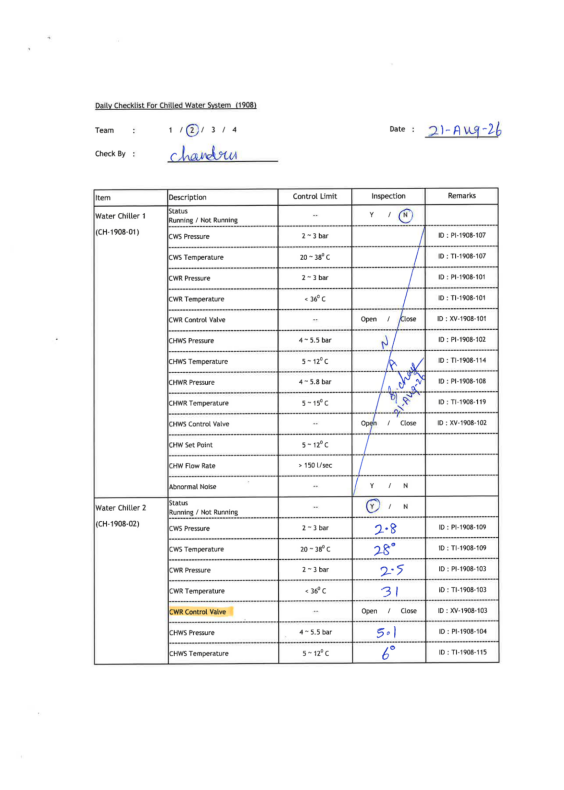

In [6]:
img = Image.open("../output/page_1.png")

plt.figure(figsize=(15,10))
plt.imshow(img)
plt.axis("off")
plt.show()

In [ ]:
for i in range(len(pdf)):
    page = pdf[i]
    pix = page.get_pixmap(matrix=fitz.Matrix(2,2))
    pix.save(f"../output/page_{i+1}.png")

print("Done")

In [ ]:
# PaddleOCR for all 4 pages TEST

import time
from paddleocr import PaddleOCR

# --------------------------
# Measure model loading time
# --------------------------
start = time.time()

ocr = PaddleOCR(
    lang="en",
    enable_mkldnn=True,
    use_textline_orientation=True
)

print(f"Model load time: {time.time() - start:.2f} seconds")

# --------------------------
# OCR all pages
# --------------------------
pages = [
    "../output/page_1.png",
    "../output/page_2.png",
    "../output/page_3.png",
    "../output/page_4.png"
]

overall_start = time.time()

for page in pages:

    print(f"\nProcessing {page}")

    page_start = time.time()

    result = ocr.predict(page)[0]

    elapsed = time.time() - page_start

    print(
        f"Found {len(result['rec_texts'])} text items "
        f"in {elapsed:.2f} seconds"
    )

total_elapsed = time.time() - overall_start

print("\n========================")
print(f"Total OCR time: {total_elapsed:.2f} seconds")
print("========================")

In [ ]:
# PaddleOCR with pdf input 
import time
from paddleocr import PaddleOCR

pdf_path = "../sample_data/2550_001.pdf"

start = time.time()

ocr = PaddleOCR(
    lang="en",
    enable_mkldnn=True,
    use_textline_orientation=False
)

print(f"Model load time: {time.time() - start:.2f}s")

ocr_start = time.time()

results = ocr.predict(pdf_path)

print(f"\nPages returned: {len(results)}")

for i, result in enumerate(results, 1):
    print(
        f"Page {i}: "
        f"{len(result['rec_texts'])} text items"
    )

print(f"\nTotal OCR time: {time.time() - ocr_start:.2f}s")

In [7]:
# Sort the OCR results into rows and columns (top to bottom, left to right)
def build_ocr_items(result):
    items = []

    for text, score, box in zip(
        result["rec_texts"],
        result["rec_scores"],
        result["rec_polys"]
    ):
        xs = [p[0] for p in box]
        ys = [p[1] for p in box]

        items.append({
            "text": text,
            "confidence": float(score),
            "x_min": min(xs),
            "x_max": max(xs),
            "y_min": min(ys),
            "y_max": max(ys),
            "center_x": sum(xs) / len(xs),
            "center_y": sum(ys) / len(ys)
        })

    return items


def group_rows(items, tolerance=15):
    rows = []

    items = sorted(
        items,
        key=lambda x: x["center_y"]
    )

    for item in items:
        found = False

        for row in rows:
            row_y = (
                sum(
                    i["center_y"]
                    for i in row
                )
                / len(row)
            )

            if abs(item["center_y"] - row_y) < tolerance:
                row.append(item)
                found = True
                break

        if not found:
            rows.append([item])

    return rows


def sort_rows(rows):
    for row in rows:
        row.sort(
            key=lambda x: x["center_x"]
        )
    return rows


def row_to_text(rows):
    output = []
    for row in rows:
        line = " | ".join(
            item["text"]
            for item in row
        )

        output.append(line)

    return output

In [8]:
SUPPORTED_IMAGES = {
    ".png",
    ".jpg",
    ".jpeg"
}

def load_pages(files):
    """
    Converts incoming files into a list of images.

    Returns:
        [
            {
                "source": "...",
                "page_number": 1,
                "image": PIL.Image
            }
        ]
    """

    pages = []

    for file in files:
        file = Path(file)

        # PDF
        if file.suffix.lower() == ".pdf":
            pdf = fitz.open(file)
            for page_idx in range(len(pdf)):
                page = pdf[page_idx]
                pix = page.get_pixmap(
                    matrix=fitz.Matrix(2, 2)
                )
                img = Image.frombytes(
                    "RGB",
                    [pix.width, pix.height],
                    pix.samples
                ).convert("RGB")

                pages.append(
                    {
                        "source": str(file),
                        "page_number": page_idx + 1,
                        "image": img
                    }
                )

        # Images
        elif file.suffix.lower() in SUPPORTED_IMAGES:
            img = Image.open(file).convert("RGB")

            pages.append(
                {
                    "source": str(file),
                    "page_number": 1,
                    "image": img
                }
            )

    return pages


# Run OCR on a list of image pages
def run_ocr(pages):
    results = []

    for page in pages:
        start = time.time()
        img_np = np.array(page["image"])
        prediction = ocr.predict(img_np)

        if not prediction:
            print(
                f"Warning: No result for "
                f"{page['source']} "
                f"Page {page['page_number']}"
            )
            continue

        result = prediction[0]

        duration = time.time() - start

        # Reconstruct the text into rows
        items = build_ocr_items(result)
        rows = group_rows(items)
        rows = sort_rows(rows)
        reconstructed_rows = row_to_text(rows)
    
        # test print
        for line in reconstructed_rows:
            print(line)

        results.append(
            {
                "source": page["source"],
                "page_number": page["page_number"],
                "time_seconds": round(duration, 2),

                "texts": result["rec_texts"],
                "scores": [
                    float(x)
                    for x in result["rec_scores"]
                ],
                # TOP LEFT, TOP_RIGHT, BOTTOM_RIGHT, BOTTOM_LEFT
                "boxes": [
                    box.tolist()
                    for box in result["rec_polys"]
                ],
                "reconstructed_rows": reconstructed_rows
            }
        )

    return results

In [9]:
def save_json(results, path):
    with open(
        path,
        "w",
        encoding="utf-8"
    ) as f:

        json.dump(
            results,
            f,
            indent=2,
            ensure_ascii=False
        )


def save_excel(results, path):
    rows = []

    for page in results:
        for text, score, box in zip(
            page["texts"],
            page["scores"],
            page["boxes"]
        ):
            rows.append(
                {
                    "source": page["source"],
                    "page": page["page_number"],
                    "text": text,
                    "confidence": score,
                    "position": json.dumps(box)
                }
            )

    df = pd.DataFrame(rows)

    df.to_excel(
        path,
        index=False
    )


def save_reconstructed_json(results, path):
    output = []
    for page in results:
        output.append(
            {
                "source": page["source"],
                "page": page["page_number"],
                "rows": page["reconstructed_rows"]
            }
        )

    with open(
        path,
        "w",
        encoding="utf-8"
    ) as f:
        json.dump(
            output,
            f,
            indent=2,
            ensure_ascii=False
        )

def save_rows_excel(results, path):
    rows_out = []
    for page in results:
        for row_num, row_text in enumerate(
            page["reconstructed_rows"],
            start=1
        ):
            rows_out.append(
                {
                    "source": page["source"],
                    "page": page["page_number"],
                    "row": row_num,
                    "text": row_text
                }
            )

    df = pd.DataFrame(rows_out)

    df.to_excel(
        path,
        index=False
    )

In [11]:
# ------------------
# TEST INPUT
# ------------------

ocr = PaddleOCR(
    lang="en",
    enable_mkldnn=True,
    use_textline_orientation=False
)
filetype = "jpg"  # pdf, jpg, png
# files = ["../sample_data/2550_001.pdf"]         # PDF

files = [
    "../sample_data/2550_001_page_1.jpg",     # JPG
    "../sample_data/2550_001_page_2.jpg",
    "../sample_data/2550_001_page_3.jpg",
    "../sample_data/2550_001_page_4.jpg"
]

# files = [
#     "../sample_data/2550_001_page_1.png",     # PNG
#     "../sample_data/2550_001_page_2.png",
#     "../sample_data/2550_001_page_3.png",
#     "../sample_data/2550_001_page_4.png"
# ]

# Convert to images
pages = load_pages(files)

print(f"Loaded {len(pages)} pages")

# OCR
results = run_ocr(pages)

# Summary
for page in results:

    print(
        f"Page {page['page_number']}: "
        f"{len(page['texts'])} text items "
        f"({page['time_seconds']} sec)"
    )

# Save outputs
save_json(
    results,
    f"../output/results_{filetype}.json"
)

save_excel(
    results,
    f"../output/results_{filetype}.xlsx"
)

save_reconstructed_json(
    results,
    f"../output/reconstructed_{filetype}.json"
)

save_rows_excel(
    results,
    f"../output/reconstructed_rows_{filetype}.xlsx"
)

print("\nDone")

Creating model: ('PP-LCNet_x1_0_doc_ori', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\VV6687\.paddlex\official_models\PP-LCNet_x1_0_doc_ori`.
Creating model: ('UVDoc', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\VV6687\.paddlex\official_models\UVDoc`.
Creating model: ('PP-OCRv6_medium_det', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\VV6687\.paddlex\official_models\PP-OCRv6_medium_det`.
Creating model: ('PP-OCRv6_medium_rec', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\VV6687\.paddlex\official_models\PP-OCRv6_medium_rec`.


Loaded 4 pages
Daily Checklist For Chilled Water System (1908)
Team | 1/②/ 3 / 4 | Date:21-Aug-26
Check By : | chandru
Item | Description | Control Limit | Inspection | Remarks
Water Chiller 1 | Status | Y / N
Running / Not Running
(CH-1908-01) | CWS Pressure | 2 ~ 3 bar | ID:PI-1908-107
CWS Temperature | 20~38°C | ID:TI-1908-107
CWR Pressure | 2~3 bar | ID:PI-1908-101
CWR Temperature | < 36°C | ID:TI-1908-101
CWR Control Valve | Open / | Close | ID:XV-1908-101
CHWS Pressure | 4 ~ 5.5 bar | N | ID:PI-1908-102
CHWS Temperature | 5~12°C | ID:TI-1908-114
CHWR Pressure | 4~5.8 bar | ID:PI-1908-108
CHWR Temperature | 5~15°C | 6 | 21-Aug- | ID : TI-1908-119
CHWS Control Valve | Open / | Close | ID:XV-1908-102
CHW Set Point | 5~12°C
CHW Flow Rate | > 150 l/sec
Abnormal Noise | Y /  N
Water Chiller 2 | Status | Y / N
Running / Not Running
(CH-1908-02) | CWS Pressure | 2 ~3 bar | 2.8 | ID:PI-1908-109
CWS Temperature | 20~38°C | 28° | ID:TI-1908-109
CWR Pressure | 2~3 bar | 2.5 | ID:PI-1908-103
